# Model training and evaluation

Create a stratified holdout split, fit preprocessing on training data only, compare baseline classifiers, tune selected models with cross-validation, evaluate on the holdout set, and save the selected pipeline and metrics.


In [2]:
from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split


student_df = pd.read_csv("../data/raw/student_mental_health.csv")
X = student_df.drop(columns=["Student_ID", "Mental_Health_Risk"])
y = student_df["Mental_Health_Risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)


Train shape: (1600, 15)
Test shape: (400, 15)


In [3]:
ordinal_columns = ["Physical_Activity", "Diet_Quality"]
numeric_columns = X_train.select_dtypes(include="number").columns.tolist()

categorical_columns = [
    col for col in X_train.select_dtypes(exclude="number").columns
    if col not in ordinal_columns
]

print(f"Variables numeriques ({len(numeric_columns)}):", numeric_columns)
print(f"Variables categorielles ({len(ordinal_columns)}):", ordinal_columns)
print(f"Variables categorielles ({len(categorical_columns)}):", categorical_columns)


Variables numeriques (10): ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
Variables categorielles (2): ['Physical_Activity', 'Diet_Quality']
Variables categorielles (3): ['Gender', 'Part_Time_Job', 'Previous_Mental_Health_History']


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    LabelEncoder,
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler,
)
from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

ordinal_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OrdinalEncoder(
                categories=[["Low", "Moderate", "High"], ["Poor", "Average", "Good"]],
                handle_unknown="use_encoded_value",
                unknown_value=-1
            ),
        ),
    ]
)

categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore"),
        ),
    ]
)

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_columns),
        ("ordinal", ordinal_pipeline, ordinal_columns),
        ("cat", categorical_pipeline, categorical_columns),
    ]
)


In [5]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

baseline_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=1,
    ),
}


In [6]:
baseline_results = []
for name, estimator in baseline_models.items():
    pipeline = Pipeline(
        [("preprocessor", preprocessor), ("model", estimator)]
    )
    scores = cross_val_score(
        pipeline,
        X_train,
        y_train_encoded,
        cv=5,
        scoring="f1_macro",
        n_jobs=2,
    )
    baseline_results.append(
        {
            "Model": name,
            "CV F1 Mean": scores.mean(),
        }
    )

baseline_results_df = (
    pd.DataFrame(baseline_results)
    .sort_values("CV F1 Mean", ascending=False)
    .reset_index(drop=True)
)


,Model,CV F1 Mean
0,Logistic Regression,0.7455
1,Random Forest,0.6791
2,Decision Tree,0.5525


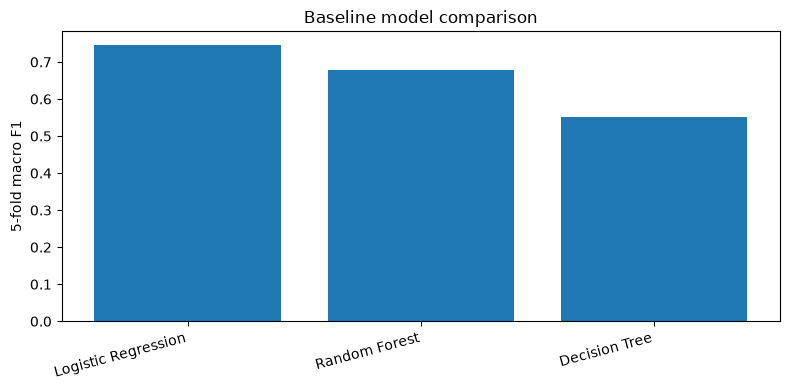

In [7]:
display(baseline_results_df.round(4))

plt.figure(figsize=(8, 4))
plt.bar(
    baseline_results_df["Model"],
    baseline_results_df["CV F1 Mean"],
    capsize=4,
)
plt.ylabel("5-fold macro F1")
plt.title("Baseline model comparison")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


In [8]:
from sklearn.model_selection import GridSearchCV

candidate_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42, n_jobs=1),
}

parameter_grids = {
    "Logistic Regression": {
            "model__C": [0.01, 0.1, 1.0, 10.0],
    },
    "Random Forest": {
        "model__n_estimators": [150, 250],
        "model__max_depth": [10, 15, 20],
        "model__min_samples_split": [2, 5],
        "model__min_samples_leaf": [1, 2],
    }
    
}

optimized_models = {}
tuning_results = []
for name, estimator in candidate_models.items():
    pipeline = Pipeline(
        [("preprocessor", preprocessor), ("model", estimator)]
    )
    search = GridSearchCV(
        pipeline,
        parameter_grids[name],
        cv=5,
        scoring="f1_macro",
        n_jobs=2,
    )
    search.fit(X_train, y_train_encoded)
    optimized_models[name] = search.best_estimator_
    tuning_results.append(
        {
            "Model": name,
            "Best CV F1-Score": search.best_score_,
            "Best Params": search.best_params_,
        }
    )

tuning_results_df = (
    pd.DataFrame(tuning_results)
    .sort_values("Best CV F1-Score", ascending=False)
)
display(tuning_results_df)


,Model,Best CV F1-Score,Best Params
0,Logistic Regression,0.746775,{'model__C': 10.0}
1,Random Forest,0.686812,"{'model__max_depth': 15, 'model__min_samples_l..."


In [10]:
best_model_name = tuning_results_df.loc[0, "Model"]
best_cv_f1 = tuning_results_df.loc[0, "Best CV F1-Score"]
# print(optimized_models[best_model_name])
best_model = optimized_models[best_model_name]
y_predicted = best_model.predict(X_test)

metrics = {
    "accuracy": accuracy_score(y_test_encoded, y_predicted),
    "precision": precision_score(
        y_test_encoded,
        y_predicted,
        average="macro",
    ),
    "recall": recall_score(
        y_test_encoded,
        y_predicted,
        average="macro",
    ),
    "f1_score": f1_score(
        y_test_encoded,
        y_predicted,
        average="macro",
    ),
}

final_results_df = pd.DataFrame(
    [
        {
            "Model selected by CV": best_model_name,
            "CV F1-Score": best_cv_f1,
            "Test Accuracy": metrics["accuracy"],
            "Test Precision": metrics["precision"],
            "Test Recall": metrics["recall"],
            "Test F1-Score": metrics["f1_score"],
        }
    ]
)
display(final_results_df.round(4))
print(f"Model selection: {best_model_name}")


,Model selected by CV,CV F1-Score,Test Accuracy,Test Precision,Test Recall,Test F1-Score
0,Logistic Regression,0.7468,0.755,0.755,0.7543,0.7546


Model selection: Logistic Regression


              precision    recall  f1-score   support

           0       0.81      0.82      0.82       136
           1       0.82      0.80      0.81       132
           2       0.63      0.64      0.63       132

    accuracy                           0.76       400
   macro avg       0.75      0.75      0.75       400
weighted avg       0.76      0.76      0.76       400



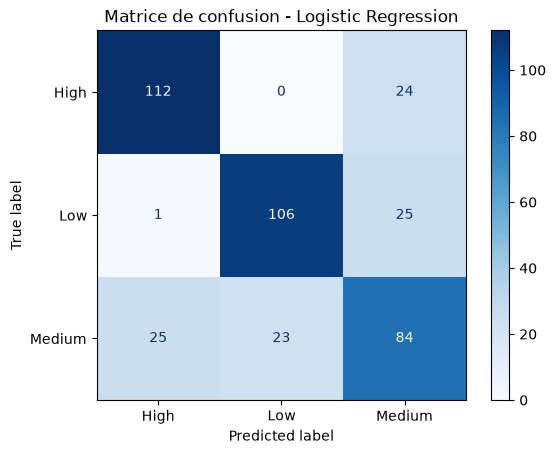

In [12]:
print(
    classification_report(
        y_test_encoded,
        y_predicted,
    )
)

ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test,
    y_test_encoded,
    display_labels=label_encoder.classes_,
    cmap="Blues",
)
plt.title(f"Matrice de confusion - {best_model_name}")
plt.show()


In [ ]:
import json
import joblib

joblib.dump(best_model, "../models/mental_health_pipeline.joblib")
joblib.dump(label_encoder, "../models/label_encoder.joblib")

cm = confusion_matrix(y_test_encoded, y_predicted)
print(cm)
data_to_save = {
    "model_name": best_model_name,
    "accuracy": round(float(metrics["accuracy"]), 4),
    "precision": round(float(metrics["precision"]), 4),
    "recall": round(float(metrics["recall"]), 4),
    "f1_score": round(float(metrics["f1_score"]), 4),
    "classes": label_encoder.classes_.tolist(),
    "confusion_matrix": cm.tolist(),
}

with open("../models/evaluation_metrics.json", "w") as f:
    json.dump(data_to_save, f)

print("Saved successfully!")

[[112   0  24]
 [  1 106  25]
 [ 25  23  84]]
Saved successfully!
